<a href="https://colab.research.google.com/github/AhmedElbanna12/Computer-Vision/blob/main/cv_task2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

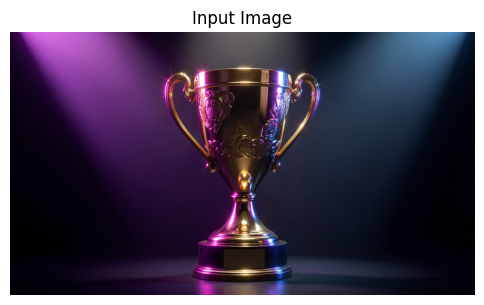

Total pixels: 2088960
Algorithm converged after 29 iterations
Final cluster centers:
[[ 16.746904  11.524319  28.107534]
 [166.47585  107.14836  171.74635 ]
 [ 64.75476   51.349064  83.22119 ]]


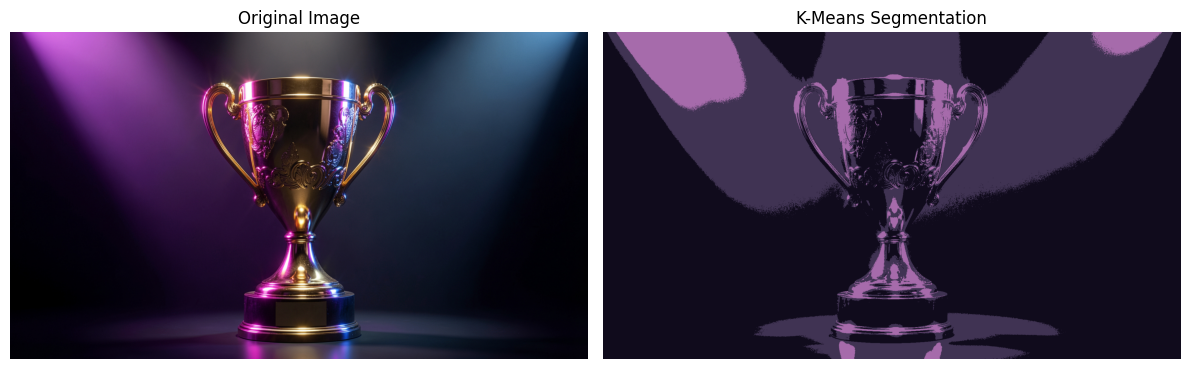

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read and display the image
img = cv2.imread(r'prize.jpg')
if img is None:
    print("Could not load the image")

else:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title("Input Image")
    plt.axis("off")
    plt.show()

    # 2. Prepare image pixels
    height, width, channels = img.shape

    pixels = img.reshape(height * width, channels).astype(np.float32)

    print("Total pixels:", len(pixels))

    # 3. Choose initial cluster centers
    num_clusters = 3

    np.random.seed(10)

    selected = np.random.permutation(len(pixels))[:num_clusters]
    cluster_centers = pixels[selected].copy()

    # 4. Run K-Means iterations
    max_iterations = 100

    for step in range(max_iterations):

        # Calculate distances between pixels and centers
        diff = pixels[:, np.newaxis, :] - cluster_centers[np.newaxis, :, :]
        distance_matrix = np.sqrt(np.sum(diff ** 2, axis=2))

        # Assign every pixel to its nearest center
        pixel_groups = np.argmin(distance_matrix, axis=1)

        # Calculate new centers
        updated_centers = cluster_centers.copy()

        for group_id in range(num_clusters):
            members = pixels[pixel_groups == group_id]

            if members.shape[0] != 0:
                updated_centers[group_id] = members.mean(axis=0)

        # Stop when centers no longer change significantly
        if np.allclose(cluster_centers, updated_centers):
            cluster_centers = updated_centers
            print("Algorithm converged after", step + 1, "iterations")
            break

        cluster_centers = updated_centers

    # 5. Create the segmented image
    final_colors = np.clip(cluster_centers, 0, 255).astype(np.uint8)

    output_pixels = final_colors[pixel_groups]
    output_img = output_pixels.reshape(height, width, channels)

    print("Final cluster centers:")
    print(cluster_centers)

    # 6. Compare original and segmented images
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(output_img)
    plt.title("K-Means Segmentation")
    plt.axis("off")

    plt.tight_layout()
    plt.show()